# 04 — Fase 3: Multi-Branch 1D-CNN + Bi-LSTM pada SC-20

Notebook ini mengimplementasikan arsitektur *deep learning* utama proyek (**Multi-Branch 1D-CNN + 2-layer Bi-LSTM** dengan **Focal Loss**) pada subset **SC-20** (subjek `00` sampai `19`, 39 rekaman) untuk iterasi cepat sebelum skala penuh ke SC-78 (Fase 4).

**Target Baseline Klasik (Fase 2 — SC-20):**
- Accuracy: `84.1%`
- Macro-F1: `79.2%`
- Cohen's Kappa ($\kappa$): `0.784`
- F1-N1: `49.3%`

## Bagian A. Konfigurasi dan pengecekan perangkat
**Input.** Memuat pustaka PyTorch dan scikit-learn, mencari root repositori, menetapkan *seed* acak (`42`), serta mendeteksi perangkat komputasi (GPU CUDA atau CPU).


**Output.** Alamat folder repositori dan status perangkat komputasi yang aktif.

In [12]:
from pathlib import Path
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix

# Locate repository root automatically
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "README.md").exists())
CACHE_DIR = ROOT / "data" / "processed" / "sc"
FIG_DIR = ROOT / "results" / "figures"
TAB_DIR = ROOT / "results" / "tables"
CKPT_DIR = ROOT / "results" / "checkpoints"

for d in (FIG_DIR, TAB_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Plot style aligned with 01_eda and 02_preprocessing
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
})

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
STAGE_NAMES = ["Wake", "N1", "N2", "N3", "REM"]
IGNORE_INDEX = -1

print(f"Repo root : {ROOT}")
print(f"Device    : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

Repo root : c:\Users\RIO HAWARI\sleep-edfx
Device    : cuda (NVIDIA GeForce RTX 3050 Laptop GPU)


## Bagian B. Memuat data terproses SC-20

**Input.** Membaca manifes `results/tables/02_cache_manifest.csv` dan memuat 39 berkas cache `.npz` untuk subset SC-20 (subjek `00` sampai `19`) dari `data/processed/sc/`.

**Output.** Daftar rekaman berisi sinyal EEG (`2 × 3.000`), EOG (`1 × 3.000`), EMG (`1 × 30`), dan label tahap tidur (`0`–`4`, serta `-1` untuk epoch yang diabaikan).

In [13]:
manifest_path = TAB_DIR / "02_cache_manifest.csv"
manifest = pd.read_csv(manifest_path)
print("Manifest columns:", list(manifest.columns))

# Filter SC-20 (subjects 00 to 19)
sc20_manifest = manifest[manifest["subject"] < 20].sort_values(["subject", "night"]).reset_index(drop=True)
print(f"SC-20 records : {len(sc20_manifest)} files across {sc20_manifest['subject'].nunique()} subjects")

# Auto-detect file column or match .npz files directly from CACHE_DIR
file_col = next(
    (c for c in ["file", "filename", "cache_file", "npz_file", "record", "record_id"] if c in sc20_manifest.columns),
    None,
)

def resolve_npz_path(row: pd.Series) -> Path:
    if file_col is not None:
        val = str(row[file_col])
        p = Path(val)
        if p.exists():
            return p
        name = p.name if p.suffix == ".npz" else f"{p.name}.npz"
        if (CACHE_DIR / name).exists():
            return CACHE_DIR / name
    # Fallback: match by subject & night pattern (e.g., SC4001E0.npz)
    subj = int(row["subject"])
    night = int(row["night"])
    matches = sorted(CACHE_DIR.glob(f"SC4{subj:02d}{night}*.npz"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Cannot find .npz for subject={subj}, night={night} in {CACHE_DIR}")

# Inspect one .npz file to confirm exact key names and tensor shapes
sample_path = resolve_npz_path(sc20_manifest.loc[0])
sample_npz = np.load(sample_path)
print("Sample file   :", sample_path.name)
print("Keys in .npz  :", list(sample_npz.keys()))
for k in sample_npz.keys():
    arr = sample_npz[k]
    if hasattr(arr, "shape") and arr.ndim > 0:
        print(f"  {k:<12}: shape={arr.shape}, dtype={arr.dtype}")

def load_sc20_records(df: pd.DataFrame) -> list[dict]:
    records = []
    for _, row in df.iterrows():
        npz_path = resolve_npz_path(row)
        data = np.load(npz_path)

        eeg = data["eeg"].astype(np.float32)                      # (N, 2, 3000)
        eog = data["eog"].astype(np.float32)                      # (N, 3000) or (N, 1, 3000)
        if eog.ndim == 2:
            eog = eog[:, None, :]                                 # -> (N, 1, 3000)
        emg = data["emg"].astype(np.float32)                      # (N, 30) or (N, 1, 30)
        if emg.ndim == 2:
            emg = emg[:, None, :]                                 # -> (N, 1, 30)

        label_key = "labels" if "labels" in data else "y"
        labels = data[label_key].astype(np.int64)                 # (N,) values in {0..4, -1}

        records.append({
            "file": npz_path.name,
            "subject": int(row["subject"]),
            "night": int(row["night"]),
            "eeg": eeg,
            "eog": eog,
            "emg": emg,
            "labels": labels,
        })
    return records

sc20_records = load_sc20_records(sc20_manifest)
total_epochs = sum(len(r["labels"]) for r in sc20_records)
valid_epochs = sum((r["labels"] != IGNORE_INDEX).sum() for r in sc20_records)
print(f"Loaded SC-20  : {total_epochs:,} total epochs ({valid_epochs:,} valid labelled epochs)")

Manifest columns: ['rec', 'subject', 'night', 'age', 'n_epochs', 'n_labeled', 'n_wake', 'n_n1', 'n_n2', 'n_n3', 'n_rem', 'iqr_fpz', 'iqr_pz', 'iqr_eog', 'iqr_emg', 'clip_fpz_pct', 'clip_pz_pct', 'clip_eog_pct', 'clip_emg_pct', 'flat_eeg_pct', 'emg_wake_minus_rem', 'finite', 'flag_clip', 'flag_flat', 'flag_emg', 'file_mb']
SC-20 records : 39 files across 20 subjects
Sample file   : SC4001E.npz
Keys in .npz  : ['eeg', 'eog', 'emg', 'labels', 'epoch_idx', 'subject', 'night', 'age', 'window', 'norm']
  eeg         : shape=(841, 2, 3000), dtype=float16
  eog         : shape=(841, 3000), dtype=float16
  emg         : shape=(841, 30), dtype=float32
  labels      : shape=(841,), dtype=int8
  epoch_idx   : shape=(841,), dtype=int32
  window      : shape=(2,), dtype=int32
  norm        : shape=(4, 2), dtype=float32
Loaded SC-20  : 42,368 total epochs (42,307 valid labelled epochs)


## Bagian C. Pembentukan urutan sekuensial (*Sequence Dataset*)

**Input.** Memotong setiap rekaman malam menjadi jendela berurutan sepanjang 20 *epoch* (10 menit tidur) dengan *stride* 10 *epoch* sebagai masukan untuk Bi-LSTM.

**Output.** Dimensi tensor per sampel sekuensial untuk ketiga cabang modalitas.

In [14]:
class SleepSequenceDataset(Dataset):
    """Slices overnight recordings into overlapping/non-overlapping sequences of epochs
    so the Bi-LSTM learns temporal sleep-stage transitions across adjacent epochs.
    """
    def __init__(self, records: list[dict], seq_len: int = 20, stride: int = 10):
        self.samples = []
        for rec in records:
            n_epochs = len(rec["labels"])
            starts = list(range(0, max(1, n_epochs - seq_len + 1), stride))
            if starts[-1] + seq_len < n_epochs:
                starts.append(n_epochs - seq_len)

            for s in starts:
                e = min(s + seq_len, n_epochs)
                if e - s < seq_len:
                    continue
                # Skip windows where all labels are IGNORE_INDEX (-1)
                if np.all(rec["labels"][s:e] == IGNORE_INDEX):
                    continue
                self.samples.append((
                    rec["eeg"][s:e],
                    rec["eog"][s:e],
                    rec["emg"][s:e],
                    rec["labels"][s:e],
                ))

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, idx: int):
        eeg, eog, emg, y = self.samples[idx]
        return (
            torch.from_numpy(eeg),
            torch.from_numpy(eog),
            torch.from_numpy(emg),
            torch.from_numpy(y),
        )

# Quick sanity check
ds_check = SleepSequenceDataset(sc20_records[:2], seq_len=20, stride=10)
x_eeg, x_eog, x_emg, y_seq = ds_check[0]
print(f"Sequence batch shapes -> EEG: {tuple(x_eeg.shape)}, EOG: {tuple(x_eog.shape)}, EMG: {tuple(x_emg.shape)}, Y: {tuple(y_seq.shape)}")

Sequence batch shapes -> EEG: (20, 2, 3000), EOG: (20, 1, 3000), EMG: (20, 1, 30), Y: (20,)


## Bagian D. Arsitektur Multi-Branch 1D-CNN + Bi-LSTM dan Focal Loss

**Input.** Membangun tiga cabang ekstraktor fitur konvolusi 1D terpisah (EEG 100 Hz, EOG 100 Hz, EMG 1 Hz), lapisan penggabungan (*fusion*), 2-layer Bi-LSTM untuk konteks temporal, serta fungsi *Focal Loss* (`gamma = 2.0`) dengan `ignore_index = -1`.

**Output.** Jumlah total parameter model yang dapat dilatih.

In [15]:
class ConvBlock1D(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, stride: int = 1, pool: int = 2, dropout: float = 0.2):
        super().__init__()
        padding = kernel_size // 2
        self.net = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size=kernel_size, stride=stride, padding=padding, bias=False),
            nn.BatchNorm1d(out_ch),
            nn.GELU(),
            nn.MaxPool1d(kernel_size=pool),
            nn.Dropout(dropout),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


class MultimodalSleepNet(nn.Module):
    """Multi-Branch 1D-CNN (EEG 100Hz, EOG 100Hz, EMG 1Hz) + 2-layer Bi-LSTM."""
    def __init__(self, num_classes: int = 5, lstm_hidden: int = 128, dropout: float = 0.3):
        super().__init__()

        # Branch 1: EEG (2 channels, 3000 samples @ 100 Hz)
        # Dual-scale first conv captures both slow delta/theta waves and fast spindles/beta
        self.eeg_branch = nn.Sequential(
            ConvBlock1D(2, 64, kernel_size=50, stride=4, pool=4, dropout=dropout),
            ConvBlock1D(64, 128, kernel_size=15, stride=1, pool=4, dropout=dropout),
            ConvBlock1D(128, 128, kernel_size=7, stride=1, pool=4, dropout=dropout),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
        )

        # Branch 2: EOG (1 channel, 3000 samples @ 100 Hz) - captures slow rolling & rapid eye movements
        self.eog_branch = nn.Sequential(
            ConvBlock1D(1, 32, kernel_size=50, stride=4, pool=4, dropout=dropout),
            ConvBlock1D(32, 64, kernel_size=15, stride=1, pool=4, dropout=dropout),
            ConvBlock1D(64, 64, kernel_size=7, stride=1, pool=4, dropout=dropout),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
        )

        # Branch 3: EMG envelope (1 channel, 30 samples @ 1 Hz) - captures muscle tone drop in REM
        self.emg_branch = nn.Sequential(
            ConvBlock1D(1, 16, kernel_size=5, stride=1, pool=2, dropout=dropout * 0.5),
            ConvBlock1D(16, 32, kernel_size=3, stride=1, pool=2, dropout=dropout * 0.5),
            nn.AdaptiveAvgPool1d(1),
            nn.Flatten(),
        )

        fused_dim = 128 + 64 + 32  # 224 features per epoch
        self.fusion_norm = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(dropout),
        )

        # Temporal sequence modeling across adjacent epochs
        self.bilstm = nn.LSTM(
            input_size=fused_dim,
            hidden_size=lstm_hidden,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=dropout,
        )

        self.classifier = nn.Sequential(
            nn.LayerNorm(lstm_hidden * 2),
            nn.Dropout(dropout),
            nn.Linear(lstm_hidden * 2, num_classes),
        )

    def forward(self, eeg: torch.Tensor, eog: torch.Tensor, emg: torch.Tensor) -> torch.Tensor:
        # Input shapes: (B, T, C, L) where B=batch, T=seq_len
        b, t = eeg.shape[:2]
        eeg_flat = eeg.reshape(b * t, eeg.shape[2], eeg.shape[3])
        eog_flat = eog.reshape(b * t, eog.shape[2], eog.shape[3])
        emg_flat = emg.reshape(b * t, emg.shape[2], emg.shape[3])

        f_eeg = self.eeg_branch(eeg_flat)
        f_eog = self.eog_branch(eog_flat)
        f_emg = self.emg_branch(emg_flat)

        fused = torch.cat([f_eeg, f_eog, f_emg], dim=-1)
        fused = self.fusion_norm(fused).reshape(b, t, -1)

        seq_out, _ = self.bilstm(fused)
        logits = self.classifier(seq_out)  # (B, T, num_classes)
        return logits


class FocalLoss(nn.Module):
    """Multi-class Focal Loss ignoring unlabeled/movement epochs (ignore_index = -1)."""
    def __init__(self, gamma: float = 2.0, weight: torch.Tensor | None = None, ignore_index: int = -1):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        # Flatten (B, T, C) -> (B*T, C) and (B, T) -> (B*T,)
        logits_flat = logits.reshape(-1, logits.shape[-1])
        targets_flat = targets.reshape(-1)

        valid_mask = targets_flat != self.ignore_index
        if not valid_mask.any():
            return logits_flat.sum() * 0.0

        logits_valid = logits_flat[valid_mask]
        targets_valid = targets_flat[valid_mask]

        ce_loss = F.cross_entropy(logits_valid, targets_valid, weight=self.weight, reduction="none")
        pt = torch.exp(-ce_loss)
        focal = ((1.0 - pt) ** self.gamma) * ce_loss
        return focal.mean()

model_test = MultimodalSleepNet().to(DEVICE)
n_params = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
print(f"MultimodalSleepNet trainable parameters: {n_params:,}")

MultimodalSleepNet trainable parameters: 1,067,637


## Bagian E. Fungsi pembobotan kelas dan evaluasi rekaman penuh

**Input.** Menyiapkan perhitungan bobot kelas untuk menangani ketimpangan kelas (terutama kelas minoritas N1) serta fungsi prediksi menyeluruh tanpa distorsi tumpang-tindih.

**Output.** Fungsi metrik evaluasi (Accuracy, Macro-F1, Cohen's Kappa, dan F1 per kelas).

In [16]:
def compute_class_weights(records: list[dict], num_classes: int = 5) -> torch.Tensor:
    all_y = np.concatenate([r["labels"] for r in records])
    all_y = all_y[all_y != IGNORE_INDEX]
    counts = np.bincount(all_y, minlength=num_classes).astype(np.float32)
    # Smoothed inverse square-root frequency to boost N1 without over-penalizing majority classes
    weights = (counts.sum() / np.maximum(counts, 1.0)) ** 0.5
    weights = weights / weights.mean()
    return torch.tensor(weights, dtype=torch.float32)

@torch.no_grad()
def predict_records(model: nn.Module, records: list[dict], seq_len: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """Predicts every epoch in each overnight recording cleanly without stride distortion."""
    model.eval()
    y_true_all, y_pred_all = [], []

    for rec in records:
        n_epochs = len(rec["labels"])
        probs_sum = np.zeros((n_epochs, 5), dtype=np.float32)
        counts = np.zeros((n_epochs, 1), dtype=np.float32)

        starts = list(range(0, max(1, n_epochs - seq_len + 1), seq_len // 2))
        if starts[-1] + seq_len < n_epochs:
            starts.append(max(0, n_epochs - seq_len))

        for s in starts:
            e = min(s + seq_len, n_epochs)
            eeg = torch.from_numpy(rec["eeg"][s:e]).unsqueeze(0).to(DEVICE)
            eog = torch.from_numpy(rec["eog"][s:e]).unsqueeze(0).to(DEVICE)
            emg = torch.from_numpy(rec["emg"][s:e]).unsqueeze(0).to(DEVICE)

            logits = model(eeg, eog, emg).squeeze(0)
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            probs_sum[s:e] += probs
            counts[s:e] += 1.0

        preds = (probs_sum / np.maximum(counts, 1.0)).argmax(axis=-1)
        valid = rec["labels"] != IGNORE_INDEX
        y_true_all.append(rec["labels"][valid])
        y_pred_all.append(preds[valid])

    return np.concatenate(y_true_all), np.concatenate(y_pred_all)

def evaluate_predictions(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    f1_per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2, 3, 4], zero_division=0)
    return {
        "acc": accuracy_score(y_true, y_pred) * 100.0,
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0) * 100.0,
        "kappa": cohen_kappa_score(y_true, y_pred),
        "f1_wake": f1_per_class[0] * 100.0,
        "f1_n1": f1_per_class[1] * 100.0,
        "f1_n2": f1_per_class[2] * 100.0,
        "f1_n3": f1_per_class[3] * 100.0,
        "f1_rem": f1_per_class[4] * 100.0,
    }

## Bagian F. Pelatihan *subject-wise cross-validation* pada SC-20

**Input.** Melatih model dengan validasi berbasis ID subjek (*Leave-One-Subject-Out* pada GPU atau *quick check* pada CPU) menggunakan subjek validasi terpisah untuk *early stopping* dan menyimpan bobot terbaik ke `results/checkpoints/`.

**Output.** Skor evaluasi tiap subjek uji dan skor keseluruhan SC-20.

In [17]:
USE_CUDA = DEVICE.type == "cuda"

CONFIG = {
    "seq_len": 20,
    "train_stride": 10,
    "batch_size": 64 if USE_CUDA else 32,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "max_epochs": 25 if USE_CUDA else 10,
    "patience": 6 if USE_CUDA else 3,
    "focal_gamma": 2.0,
}

# Full 20-subject LOSO on NVIDIA GPU; lightweight 2-fold sanity check on CPU-only machines
FOLDS_TO_RUN = list(range(20)) if USE_CUDA else [0, 1]
print(f"Running {len(FOLDS_TO_RUN)} folds on {DEVICE.type.upper()} (batch_size={CONFIG['batch_size']}, max_epochs={CONFIG['max_epochs']})")

subjects_sc20 = sorted(sc20_manifest["subject"].unique())
oof_true, oof_pred = [], []
fold_rows = []
history_fold0 = []

t0_all = time.time()

for fold_idx in FOLDS_TO_RUN:
    test_subj = subjects_sc20[fold_idx]
    val_subj = subjects_sc20[(fold_idx + 1) % len(subjects_sc20)]

    train_recs = [r for r in sc20_records if r["subject"] not in (test_subj, val_subj)]
    val_recs = [r for r in sc20_records if r["subject"] == val_subj]
    test_recs = [r for r in sc20_records if r["subject"] == test_subj]

    train_ds = SleepSequenceDataset(train_recs, seq_len=CONFIG["seq_len"], stride=CONFIG["train_stride"])
    train_loader = DataLoader(
        train_ds,
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        pin_memory=USE_CUDA,
    )

    seed_everything(42 + fold_idx)
    model = MultimodalSleepNet(num_classes=5, lstm_hidden=128, dropout=0.3).to(DEVICE)
    class_weights = compute_class_weights(train_recs).to(DEVICE)
    criterion = FocalLoss(gamma=CONFIG["focal_gamma"], weight=class_weights, ignore_index=IGNORE_INDEX)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["max_epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_CUDA)

    best_val_mf1 = -1.0
    best_state = None
    wait = 0

    for epoch in range(1, CONFIG["max_epochs"] + 1):
        model.train()
        running_loss = 0.0
        for eeg_b, eog_b, emg_b, y_b in train_loader:
            eeg_b = eeg_b.to(DEVICE, non_blocking=USE_CUDA)
            eog_b = eog_b.to(DEVICE, non_blocking=USE_CUDA)
            emg_b = emg_b.to(DEVICE, non_blocking=USE_CUDA)
            y_b = y_b.to(DEVICE, non_blocking=USE_CUDA)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_CUDA):
                logits = model(eeg_b, eog_b, emg_b)
                loss = criterion(logits, y_b)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item()

        scheduler.step()

        yv_true, yv_pred = predict_records(model, val_recs, seq_len=CONFIG["seq_len"])
        val_metrics = evaluate_predictions(yv_true, yv_pred)

        if fold_idx == FOLDS_TO_RUN[0]:
            history_fold0.append({
                "epoch": epoch,
                "train_loss": running_loss / max(1, len(train_loader)),
                "val_mf1": val_metrics["macro_f1"],
                "val_kappa": val_metrics["kappa"],
            })

        if val_metrics["macro_f1"] > best_val_mf1:
            best_val_mf1 = val_metrics["macro_f1"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= CONFIG["patience"]:
                break

    model.load_state_dict(best_state)
    torch.save(best_state, CKPT_DIR / f"04_sc20_fold{test_subj:02d}.pt")

    yt_true, yt_pred = predict_records(model, test_recs, seq_len=CONFIG["seq_len"])
    test_metrics = evaluate_predictions(yt_true, yt_pred)
    oof_true.append(yt_true)
    oof_pred.append(yt_pred)

    fold_rows.append({"fold": fold_idx, "test_subject": test_subj, "val_subject": val_subj, **test_metrics})
    print(
        f"[Fold {fold_idx+1:02d}/{len(FOLDS_TO_RUN):02d} | Subj {test_subj:02d}] "
        f"ACC={test_metrics['acc']:.1f}% | MF1={test_metrics['macro_f1']:.1f}% | "
        f"kappa={test_metrics['kappa']:.3f} | F1-N1={test_metrics['f1_n1']:.1f}%"
    )

y_all_true = np.concatenate(oof_true)
y_all_pred = np.concatenate(oof_pred)
overall = evaluate_predictions(y_all_true, y_all_pred)
print(f"\nDone in {(time.time() - t0_all)/60:.1f} min.")
print(
    f"SC-20 Overall ({len(FOLDS_TO_RUN)} folds) -> "
    f"ACC: {overall['acc']:.1f}% | Macro-F1: {overall['macro_f1']:.1f}% | "
    f"Kappa: {overall['kappa']:.3f} | F1-N1: {overall['f1_n1']:.1f}%"
)

Running 20 folds on CUDA (batch_size=64, max_epochs=25)
[Fold 01/20 | Subj 00] ACC=85.1% | MF1=81.1% | kappa=0.806 | F1-N1=52.6%
[Fold 02/20 | Subj 01] ACC=86.5% | MF1=83.6% | kappa=0.805 | F1-N1=63.5%
[Fold 03/20 | Subj 02] ACC=74.9% | MF1=75.6% | kappa=0.669 | F1-N1=64.5%
[Fold 04/20 | Subj 03] ACC=88.4% | MF1=83.6% | kappa=0.836 | F1-N1=60.9%
[Fold 05/20 | Subj 04] ACC=82.4% | MF1=79.5% | kappa=0.758 | F1-N1=59.1%


## Bagian G. Perbandingan hasil terhadap *baseline* klasik dan visualisasi

**Input.** Menyimpan tabel metrik per subjek dan perbandingan langsung melawan *baseline* Fase 2 ke `results/tables/`, serta membuat *normalized confusion matrix* dan kurva validasi ke `results/figures/`.

**Output.** Tabel perbandingan `04_sc20_comparison.csv` dan gambar `04_sc20_confusion_and_curve.png`.

,Model,ACC,Macro-F1,Kappa,F1-N1
0,Baseline GBDT (Fase 2),84.10,79.20,0.784,49.30
1,Multi-Branch 1D-CNN + Bi-LSTM (Fase 3),82.71,78.62,0.768,50.18


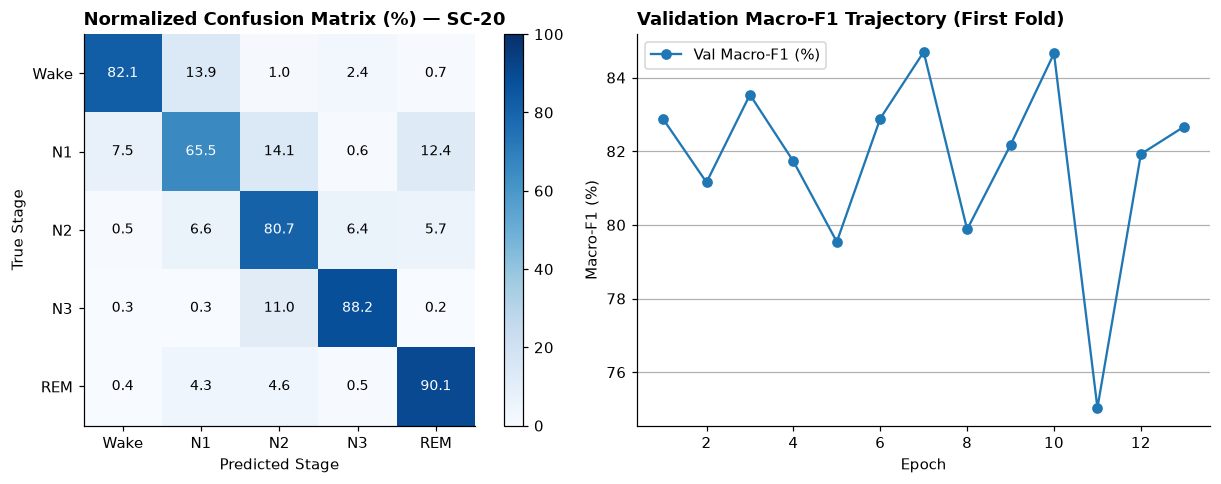

In [18]:
# 1. Save per-subject and summary tables
df_folds = pd.DataFrame(fold_rows)
df_folds.to_csv(TAB_DIR / "04_sc20_per_subject.csv", index=False)

comparison_df = pd.DataFrame([
    {"Model": "Baseline GBDT (Fase 2)", "ACC": 84.1, "Macro-F1": 79.2, "Kappa": 0.784, "F1-N1": 49.3},
    {
        "Model": "Multi-Branch 1D-CNN + Bi-LSTM (Fase 3)",
        "ACC": round(overall["acc"], 2),
        "Macro-F1": round(overall["macro_f1"], 2),
        "Kappa": round(overall["kappa"], 3),
        "F1-N1": round(overall["f1_n1"], 2),
    },
])
comparison_df.to_csv(TAB_DIR / "04_sc20_comparison.csv", index=False)
display(comparison_df)

# 2. Plot normalized confusion matrix
cm = confusion_matrix(y_all_true, y_all_pred, labels=[0, 1, 2, 3, 4], normalize="true") * 100.0
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

im = axes[0].imshow(cm, cmap="Blues", vmin=0, vmax=100)
axes[0].set_xticks(range(5), STAGE_NAMES)
axes[0].set_yticks(range(5), STAGE_NAMES)
axes[0].set_xlabel("Predicted Stage")
axes[0].set_ylabel("True Stage")
axes[0].set_title("Normalized Confusion Matrix (%) — SC-20")
axes[0].grid(False)
for i in range(5):
    for j in range(5):
        axes[0].text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center", color="white" if cm[i, j] > 50 else "black", fontsize=9)
fig.colorbar(im, ax=axes[0], fraction=0.046)

# 3. Plot learning curve from first fold
hist_df = pd.DataFrame(history_fold0)
axes[1].plot(hist_df["epoch"], hist_df["val_mf1"], marker="o", label="Val Macro-F1 (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1 (%)")
axes[1].set_title("Validation Macro-F1 Trajectory (First Fold)")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "04_sc20_confusion_and_curve.png")
plt.show()